# 01 · Probabilidad clásica

El modelo de Laplace con conjuntos de Python: espacios muestrales finitos, eventos, la ley de una variable aleatoria, probabilidad condicional e independencia, y el paso a la noción frecuentista.

**Contenido**

1. El modelo de Laplace
2. Lanzamiento de dos dados
3. La ley de la suma
4. Tres monedas: condicionamiento e independencia
5. Frecuencias relativas
6. Ejercicio resuelto: dos urnas

In [1]:
from collections import Counter
from fractions import Fraction
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)

## 1. El modelo de Laplace

Un **experimento aleatorio** tiene un conjunto de resultados posibles, el **espacio muestral** $\Omega$, que aquí suponemos finito. Un **evento** es un subconjunto $A\subseteq\Omega$. En el modelo clásico todos los resultados son equiprobables:

$$\mathbb{P}(\{\omega\})=\frac{1}{\#\Omega}\quad(\omega\in\Omega), \qquad\text{y por aditividad}\qquad \mathbb{P}(A)=\frac{\#A}{\#\Omega}.$$

Con `Fraction` las probabilidades se calculan de forma exacta.

In [2]:
def P(A, Omega):
    """Probabilidad clásica de A ⊆ Omega."""
    return Fraction(len(A & Omega), len(Omega))

## 2. Lanzamiento de dos dados

Se lanzan dos dados honestos. El espacio muestral está formado por las parejas ordenadas

$$\Omega=\{(i,j):1\le i,j\le 6\}=\{1,\dots,6\}^2,\qquad \#\Omega=6^2=36.$$

In [3]:
caras = range(1, 7)
Omega = set(product(caras, repeat=2))
len(Omega)

36

### Eventos

Sea $S_n$ el evento «la suma de los dados es $n$»:

$$S_n=\{(i,j)\in\Omega:\ i+j=n\}.$$

In [4]:
def S(n):
    return {(i, j) for (i, j) in Omega if i + j == n}

S(9)

{(3, 6), (4, 5), (5, 4), (6, 3)}

$S_n=\varnothing$ si $n\notin\{2,\dots,12\}$, y los eventos $S_2,\dots,S_{12}$ forman una partición de $\Omega$; por eso

$$\sum_{n=2}^{12}\mathbb{P}(S_n)=1.$$

In [5]:
print(S(1) == S(13) == set())
print("P(S_9) =", P(S(9), Omega))
print("Σ P(S_n) =", sum(P(S(n), Omega) for n in range(2, 13)))

True
P(S_9) = 1/9
Σ P(S_n) = 1


Sea $T_n$ el evento «el primer dado excede al segundo en al menos $n$»:

$$T_n=\{(i,j)\in\Omega:\ i-j\ge n\}.$$

In [6]:
def T(n):
    return {(i, j) for (i, j) in Omega if i - j >= n}

sorted(T(3)), P(T(3), Omega)

([(4, 1), (5, 1), (5, 2), (6, 1), (6, 2), (6, 3)], Fraction(1, 6))

## 3. La ley de la suma

La suma define una **variable aleatoria** $S:\Omega\to\{2,\dots,12\}$, $S(i,j)=i+j$. Su **ley** (o distribución) es la colección de pares $(k,p_k)$ con

$$p_k=\mathbb{P}(S=k)=\mathbb{P}(\{\omega\in\Omega: S(\omega)=k\}).$$

Para calcularla basta contar cuántos resultados producen cada valor.

In [7]:
conteo = Counter(i + j for (i, j) in Omega)
ley_S = pd.Series({k: Fraction(c, len(Omega)) for k, c in sorted(conteo.items())}, name="P(S=k)")
ley_S

2     1/36
3     1/18
4     1/12
5      1/9
6     5/36
7      1/6
8     5/36
9      1/9
10    1/12
11    1/18
12    1/36
Name: P(S=k), dtype: object

La ley tiene la forma cerrada $p_k=\dfrac{6-|k-7|}{36}$ para $2\le k\le 12$.

In [8]:
all(ley_S[k] == Fraction(6 - abs(k - 7), 36) for k in range(2, 13))

True

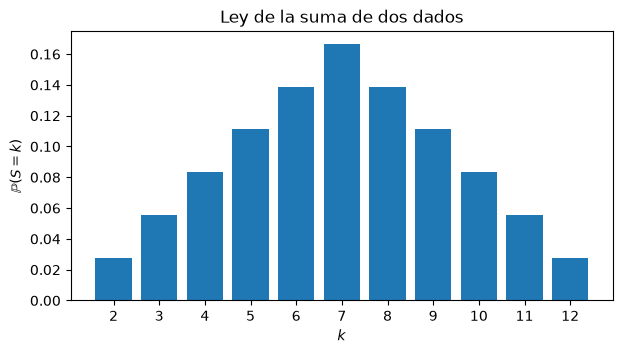

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ley_S.index, ley_S.astype(float), color="tab:blue")
ax.set_xticks(range(2, 13))
ax.set_xlabel("$k$")
ax.set_ylabel(r"$\mathbb{P}(S=k)$")
ax.set_title("Ley de la suma de dos dados")
plt.show()

## 4. Tres monedas: condicionamiento e independencia

Se lanzan tres monedas justas de manera independiente; cada una cae águila (`A`) o sol (`S`):

$$\Omega=\{A,S\}^3,\qquad \#\Omega=2^3=8.$$

In [10]:
Omega3 = set(product("AS", repeat=3))
sorted(Omega3)

[('A', 'A', 'A'),
 ('A', 'A', 'S'),
 ('A', 'S', 'A'),
 ('A', 'S', 'S'),
 ('S', 'A', 'A'),
 ('S', 'A', 'S'),
 ('S', 'S', 'A'),
 ('S', 'S', 'S')]

Sea $A_i$ el evento «el $i$-ésimo lanzamiento es águila». El evento $E$: «las tres monedas caen águila» es $E=A_1\cap A_2\cap A_3$.

In [11]:
A = {i: {w for w in Omega3 if w[i - 1] == "A"} for i in (1, 2, 3)}

E = A[1] & A[2] & A[3]
E_bis = {w for w in Omega3 if w.count("A") == 3}   # la misma descripción con .count
print(E, E == E_bis, P(E, Omega3))

{('A', 'A', 'A')} True 1/8


El evento $F$: «águila en el primero y en el segundo lanzamiento» es $A_1\cap A_2$.

In [12]:
F = A[1] & A[2]
P(F, Omega3)

Fraction(1, 4)

### Probabilidad condicional

Sea $(\Omega,\mathcal{A},\mathbb{P})$ un espacio de probabilidad y $F\in\mathcal{A}$ con $\mathbb{P}(F)>0$. La **probabilidad condicional** dado $F$ es

$$\mathbb{P}(E\mid F)=\frac{\mathbb{P}(E\cap F)}{\mathbb{P}(F)},\qquad E\in\mathcal{A}.$$

La función $\mathbb{P}(\,\cdot\mid F)$ es de nuevo una medida de probabilidad, concentrada en $F$. En el modelo clásico, $\mathbb{P}(E\mid F)=\#(E\cap F)/\#F$: se cuenta dentro de $F$.

In [13]:
def P_cond(E, F):
    return Fraction(len(E & F), len(F))

P_cond(E, A[1])

Fraction(1, 4)

¿Cuál es la probabilidad de obtener sol en el segundo lanzamiento dado que el primero fue águila? Sea $B_2$ el evento «sol en el segundo lanzamiento».

In [14]:
B2 = {w for w in Omega3 if w[1] == "S"}
print("P(B2 | A1) =", P_cond(B2, A[1]))
print("complemento:", P_cond(B2, A[1]) == 1 - P_cond(A[2], A[1]))

P(B2 | A1) = 1/2
complemento: True


### Independencia

Dos eventos son **independientes** si $\mathbb{P}(E\cap F)=\mathbb{P}(E)\,\mathbb{P}(F)$; si $\mathbb{P}(F)>0$, esto equivale a $\mathbb{P}(E\mid F)=\mathbb{P}(E)$. Los eventos $A_1,A_2,A_3$ son mutuamente independientes: la igualdad vale para cada subfamilia.

In [15]:
def independientes(E, F, Omega):
    return P(E & F, Omega) == P(E, Omega) * P(F, Omega)

print(independientes(A[1], A[2], Omega3), independientes(A[1], B2, Omega3))
print(P(A[1] & A[2] & A[3], Omega3) == P(A[1], Omega3) * P(A[2], Omega3) * P(A[3], Omega3))

True True
True


En cambio, $E$ y $A_1$ no son independientes: saber que el primer lanzamiento fue águila duplica la probabilidad de $E$.

In [16]:
P(E, Omega3), P_cond(E, A[1])

(Fraction(1, 8), Fraction(1, 4))

## 5. Frecuencias relativas

En el **enfoque frecuentista**, si un experimento se repite $n$ veces y $n(A)$ es el número de veces que ocurre $A$, la frecuencia relativa es

$$f_n(A)=\frac{n(A)}{n}.$$

La ley de los grandes números garantiza que $f_n(A)\to\mathbb{P}(A)$ casi seguramente. Lo vemos con una moneda cargada que cae sol con probabilidad $p=0.63$.

In [17]:
def volados(p, n):
    """n lanzamientos de una moneda que cae sol con probabilidad p."""
    return np.where(rng.random(n) < p, "sol", "águila")

muestra = volados(0.7, 10)
print(muestra, "\nsoles:", (muestra == "sol").sum())

['sol' 'sol' 'sol' 'sol' 'sol' 'águila' 'águila' 'sol' 'sol' 'sol'] 
soles: 8


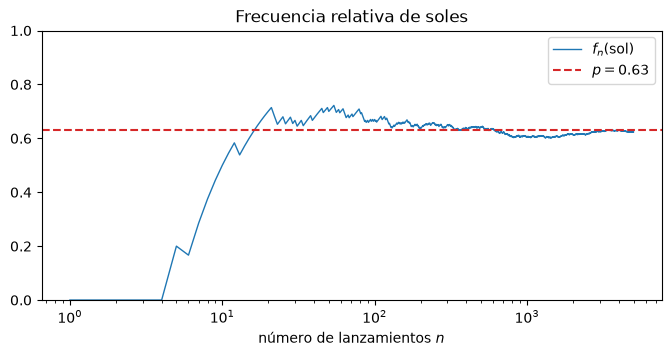

f_5000 = 0.6234


In [18]:
p, n = 0.63, 5000
soles = volados(p, n) == "sol"
f_n = np.cumsum(soles) / np.arange(1, n + 1)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, n + 1), f_n, lw=1, label="$f_n$(sol)")
ax.axhline(p, color="tab:red", ls="--", label=f"$p={p}$")
ax.set_xscale("log")
ax.set_xlabel("número de lanzamientos $n$")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Frecuencia relativa de soles")
plt.show()
print(f"f_{n} = {f_n[-1]:.4f}")

Repetir $1000$ veces un bloque de $N=10$ lanzamientos y promediar las proporciones también estima $p$, porque la proporción de un bloque es un estimador insesgado.

In [19]:
proporciones = (rng.random((1000, 10)) < 0.63).mean(axis=1)
print(f"promedio de las proporciones: {proporciones.mean():.3f}")

promedio de las proporciones: 0.628


## 6. Ejercicio resuelto: dos urnas

Se tienen dos urnas, cada una con $10$ bolas numeradas del $1$ al $10$. Se extrae al azar una bola de cada urna. ¿Cuál es la probabilidad de que los dos números difieran en $2$ o más?

**Solución.** El espacio muestral es $\Omega=\{1,\dots,10\}^2$, con $\#\Omega=100$, y el evento es

$$A=\{(i,j)\in\Omega:\ |i-j|\ge 2\}.$$

Es más corto contar el complemento $A^c=\{(i,j):|i-j|\le 1\}$: la diagonal aporta $10$ parejas y cada una de las dos subdiagonales $j=i\pm1$ aporta $9$. Así $\#A^c=28$ y

$$\mathbb{P}(A)=1-\mathbb{P}(A^c)=1-\frac{28}{100}=\frac{18}{25}.$$

Contando directamente: para cada diferencia $d=j-i\in\{2,\dots,9\}$ hay $10-d$ parejas, y lo mismo para $d\le -2$, de modo que $\#A=2(8+7+\cdots+1)=72$.

In [20]:
Omega_urnas = set(product(range(1, 11), repeat=2))
A_urnas = {(i, j) for (i, j) in Omega_urnas if abs(i - j) >= 2}
P(A_urnas, Omega_urnas)

Fraction(18, 25)

## Ejercicios

1. Calcula la ley de $M=\max(i,j)$ para dos dados y verifica que $\mathbb{P}(M=k)=\dfrac{2k-1}{36}$.
2. ¿Son independientes $S_7$ y $A=\{$el primer dado es par$\}$? ¿Y $S_8$ y $A$?
3. Simula $f_n(S_7)$ para $n$ hasta $10^5$ y compárala con $\mathbb{P}(S_7)=1/6$.